In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv("/content/agriculture_dataset_kaggle.csv")

df["stress_t"] = df["Crop_Health_Label"].astype(pd.Int64Dtype())

In [ ]:
def forecast_stress(row):
    # Initialize s, handling potential pd.NA from 'stress_t'.
    # If 'stress_t' is NA, start with 0 stress.
    s = 0 if pd.isna(row["stress_t"]) else row["stress_t"]

    # Water stress
    # Check if 'Soil_Moisture' is not NA before comparison
    if not pd.isna(row["Soil_Moisture"]) and row["Soil_Moisture"] < 0.35:
        s += 1

    # Vegetation stress
    # Check if 'NDVI' and 'Chlorophyll_Content' are not NA before comparison
    if (not pd.isna(row["NDVI"]) and row["NDVI"] < 0.4) or \
       (not pd.isna(row["Chlorophyll_Content"]) and row["Chlorophyll_Content"] < 0.4):
        s += 1

    # Biotic stress
    # Check if 'Pest_Damage' is not NA before comparison
    if not pd.isna(row["Pest_Damage"]) and row["Pest_Damage"] > 0.6:
        s += 1

    # Climatic stress
    # Check if 'Temperature' and 'Rainfall' are not NA before comparison
    if (not pd.isna(row["Temperature"]) and row["Temperature"] > 35) or \
       (not pd.isna(row["Rainfall"]) and row["Rainfall"] < 0.3):
        s += 1

    return min(s, 4)

df["stress_forecast"] = df.apply(forecast_stress, axis=1)

In [ ]:
def recommend_action(row):
    if row["stress_forecast"] <= 1:
        return "No Action"

    if row["Soil_Moisture"] < 0.35:
        return "Irrigation"

    if row["Chlorophyll_Content"] < 0.4:
        return "Nitrogen Fertilization"

    if row["Pest_Damage"] > 0.6:
        return "Pest Control"

    return "Crop Switch"

df["recommended_action"] = df.apply(recommend_action, axis=1)


In [ ]:
from sklearn.ensemble import RandomForestClassifier
import shap

# Define feature columns
feature_cols = [
    'High_Resolution_RGB', 'Multispectral_Images', 'Thermal_Images',
    'Soil_Moisture', 'NDVI', 'Chlorophyll_Content',
    'Pest_Damage', 'Temperature', 'Rainfall'
]

X_model = df[feature_cols].values
y_model = df["stress_forecast"]

model = RandomForestClassifier(
    n_estimators=200,
    max_depth=7,
    random_state=42
)
model.fit(X_model, y_model)

RandomForestClassifier(max_depth=7, n_estimators=200, random_state=42)

In [ ]:
explainer = shap.Explainer(model, X_model)
shap_values = explainer(X_model)


100%|===================| 117128/117225 [17:44<00:00]       

ExplainerError: Additivity check failed in TreeExplainer! Please ensure the data matrix you passed to the explainer is the same shape that the model was trained on. If your data shape is correct then please report this on GitHub. This check failed because for one of the samples the sum of the SHAP values was 0.011245, while the model output was 0.001052. If this difference is acceptable you can set check_additivity=False to disable this check.

In [ ]:
def discretize(series, bins):
    return np.digitize(series, bins)

df["ndvi_bin"] = discretize(df["NDVI"], [0.3, 0.5, 0.7])
df["soil_bin"] = discretize(df["Soil_Moisture"], [0.3, 0.5])
df["temp_bin"] = discretize(df["Temperature"], [25, 35])
df["pest_bin"] = discretize(df["Pest_Damage"], [0.3, 0.6])


In [ ]:
state_cols = [
    "stress_t",
    "ndvi_bin",
    "soil_bin",
    "temp_bin",
    "pest_bin",
    "Crop_Growth_Stage"
]

states = df[state_cols].values

# Action space
actions = [0, 1, 2]  # Δstress


In [ ]:
from collections import defaultdict

Q = defaultdict(lambda: np.zeros(len(actions)))

alpha = 0.1   # learning rate
gamma = 0.9   # discount
epsilon = 0.2 # exploration


In [ ]:
df['stress_t_plus_1'] = df['stress_t'].shift(-1)

for episode in range(10):  # small, stable training
    for i in range(len(states)):
        s = tuple(states[i])
        true_next = df.loc[i, "stress_t_plus_1"]

        # Skip if true_next is NA
        if pd.isna(true_next):
            continue

        # ε-greedy action
        if np.random.rand() < epsilon:
            a = np.random.choice(len(actions))
        else:
            a = np.argmax(Q[s])

        predicted = min(df.loc[i, "stress_t"] + actions[a], 4)

        # Reward: forecasting accuracy
        reward = -abs(predicted - true_next)

        # Update
        Q[s][a] += alpha * (reward - Q[s][a])

In [ ]:
df['stress_t_plus_1'] = df['stress_t'].shift(-1)

In [ ]:
display(df[['stress_t', 'stress_t_plus_1']].head())

,stress_t,stress_t_plus_1
0,1,1
1,1,1
2,1,0
3,0,0
4,0,0


In [ ]:
def rl_forecast(row):
    # Handle potential pd.NA in 'stress_t' by replacing it with 0 for calculation
    current_stress = 0 if pd.isna(row["stress_t"]) else row["stress_t"]

    s = tuple(row[state_cols])
    # Q can be empty for unseen states, so provide a default action if s is not in Q
    if s in Q:
        a = np.argmax(Q[s])
    else:
        # Default to no change in stress if state is not in Q
        a = 0 # Corresponds to actions[0] = 0

    return min(current_stress + actions[a], 4)

df["stress_forecast_rl"] = df.apply(rl_forecast, axis=1)

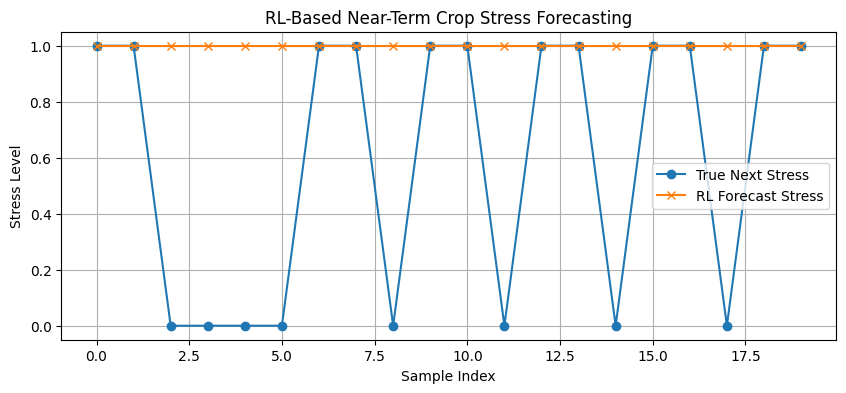

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,4))
plt.plot(df["stress_t_plus_1"][:20], label="True Next Stress", marker="o")
plt.plot(df["stress_forecast_rl"][:20], label="RL Forecast Stress", marker="x")
plt.xlabel("Sample Index")
plt.ylabel("Stress Level")
plt.title("RL-Based Near-Term Crop Stress Forecasting")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
mae = np.mean(
    abs(df["stress_forecast_rl"] - df["stress_t_plus_1"])
)

print("Mean Absolute Error (Stress Forecast):", mae)


Mean Absolute Error (Stress Forecast): 0.3043230944254835


In [ ]:
def rl_recommend_action(row):
    if row["stress_forecast_rl"] <= 1:
        return "No Action"
    if row["Soil_Moisture"] < 0.35:
        return "Irrigation"
    if row["Pest_Damage"] > 0.6:
        return "Pest Control"
    return "Nutrient Management"

df["recommended_action_rl"] = df.apply(rl_recommend_action, axis=1)


In [ ]:
def rl_recommend_action(row):

    # 1. Low forecast stress → no action
    if row["stress_forecast_rl"] <= 1:
        return "No Action"

    # 2. Water stress (primary driver)
    if row["Soil_Moisture"] < 0.35 or row["NDVI"] < 0.4:
        return "Irrigation"

    # 3. Biotic stress
    if row["Pest_Damage"] > 0.6 or row["Pest_Hotspots"] > 0.5:
        return "Pest Control"

    # 4. Nutrient stress
    if (
        row["Chlorophyll_Content"] < 0.4 or
        row["Soil_pH"] < 5.5 or
        row["Organic_Matter"] < 0.3
    ):
        return "Nutrient Management"

    # 5. Severe / late-stage stress
    if row["Crop_Growth_Stage"] > 4 and row["stress_forecast_rl"] >= 3:
        return "Crop Switch"

    return "Nutrient Management"


In [ ]:
df[[
    "stress_forecast_rl",
    "Soil_Moisture",
    "NDVI",
    "Pest_Damage",
    "Chlorophyll_Content",
    "Crop_Growth_Stage",
    "recommended_action_rl"
]].head(10)


,stress_forecast_rl,Soil_Moisture,NDVI,Pest_Damage,Chlorophyll_Content,Crop_Growth_Stage,recommended_action_rl
0,1,31.010549,0.676945,84.0,0.829063,2.0,No Action
1,1,12.429003,0.414781,56.0,0.435861,3.0,No Action
2,1,28.454713,0.723610,38.0,1.001452,1.0,No Action
3,1,28.450994,0.405611,27.0,0.962720,2.0,No Action
4,1,8.295005,0.465992,84.0,2.111205,4.0,No Action
5,1,33.794402,0.507520,1.0,2.796577,1.0,No Action
6,1,27.373834,0.499019,58.0,1.326519,1.0,No Action
7,1,21.662215,0.602585,37.0,0.502141,2.0,No Action
8,1,7.052581,0.500893,21.0,0.253741,3.0,No Action
9,1,30.577633,0.558419,91.0,0.799938,3.0,No Action


In [ ]:
from sklearn.preprocessing import MinMaxScaler

scale_cols = [
    "Soil_Moisture",
    "Pest_Damage",
    "Chlorophyll_Content"
]

scaler = MinMaxScaler()
df[scale_cols] = scaler.fit_transform(df[scale_cols])


In [ ]:
from sklearn.preprocessing import MinMaxScaler

scale_cols = [
    "Soil_Moisture",
    "Pest_Damage",
    "Chlorophyll_Content"
]

scaler = MinMaxScaler()
df[scale_cols] = scaler.fit_transform(df[scale_cols])


In [ ]:
df["recommended_action_rl"] = df.apply(rl_recommend_action, axis=1)


In [ ]:
df[[
    "stress_forecast_rl",
    "Soil_Moisture",
    "Pest_Damage",
    "Chlorophyll_Content",
    "recommended_action_rl"
]].head(10)


,stress_forecast_rl,Soil_Moisture,Pest_Damage,Chlorophyll_Content,recommended_action_rl
0,1,0.867569,0.848485,0.157162,No Action
1,1,0.247788,0.565657,0.082294,No Action
2,1,0.782320,0.383838,0.189986,No Action
3,1,0.782196,0.272727,0.182611,No Action
4,1,0.109899,0.848485,0.401290,No Action
5,1,0.960424,0.010101,0.531790,No Action
6,1,0.746268,0.585859,0.251881,No Action
7,1,0.555759,0.373737,0.094914,No Action
8,1,0.068459,0.212121,0.047617,No Action
9,1,0.853130,0.919192,0.151616,No Action


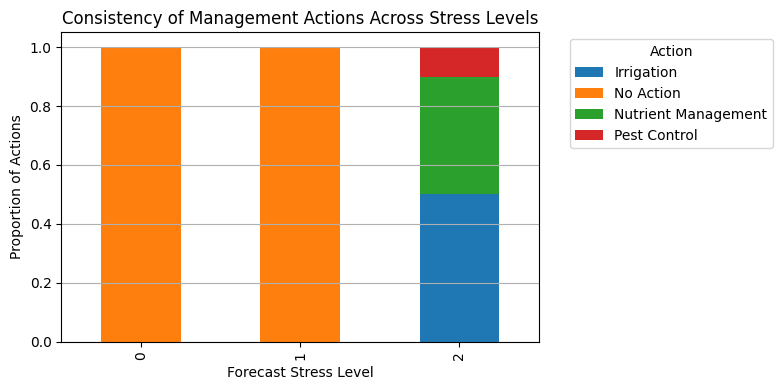

In [ ]:
import matplotlib.pyplot as plt

# Normalize counts to proportions
action_dist = (
    df.groupby("stress_forecast_rl")["recommended_action_rl"]
      .value_counts(normalize=True)
      .unstack()
      .fillna(0)
)

# Plot normalized stacked bar chart
action_dist.plot(
    kind="bar",
    stacked=True,
    figsize=(8,4)
)

plt.ylabel("Proportion of Actions")
plt.xlabel("Forecast Stress Level")
plt.title("Consistency of Management Actions Across Stress Levels")
plt.legend(title="Action", bbox_to_anchor=(1.05, 1))
plt.grid(axis="y")
plt.tight_layout()
plt.show()


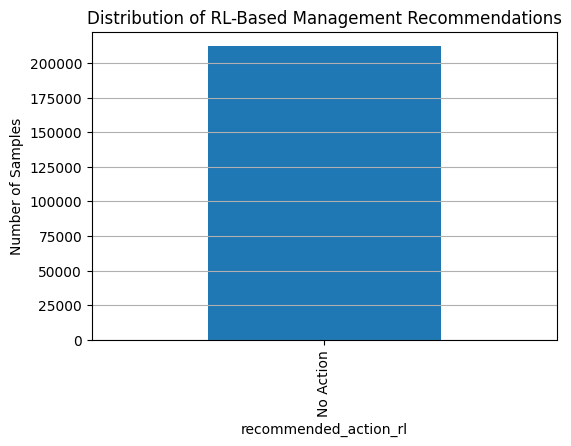

In [ ]:
df["recommended_action_rl"].value_counts().plot(
    kind="bar", figsize=(6,4)
)
plt.ylabel("Number of Samples")
plt.title("Distribution of RL-Based Management Recommendations")
plt.grid(axis="y")
plt.show()


In [ ]:
# stress_forecast_rl = 1  (for all shown rows)

### Distribution of Crop Growth Stage

/tmp/ipython-input-2985424535.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Crop_Growth_Stage', data=df, palette='viridis')


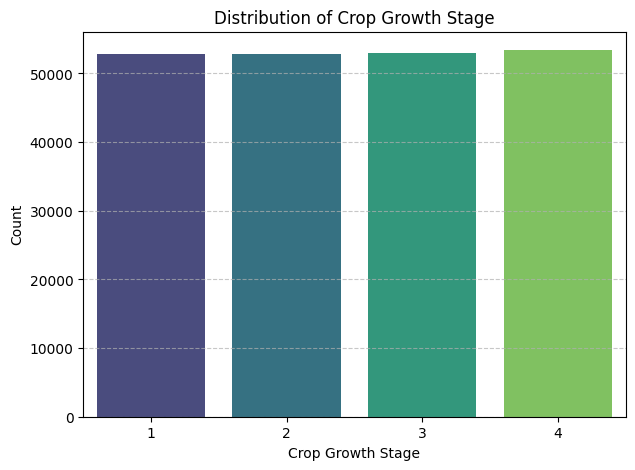

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))
sns.countplot(x='Crop_Growth_Stage', data=df, palette='viridis')
plt.title('Distribution of Crop Growth Stage')
plt.xlabel('Crop Growth Stage')
plt.ylabel('Count')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### Distribution of NDVI Bins

/tmp/ipython-input-3806333152.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='ndvi_bin', data=df, palette='magma')


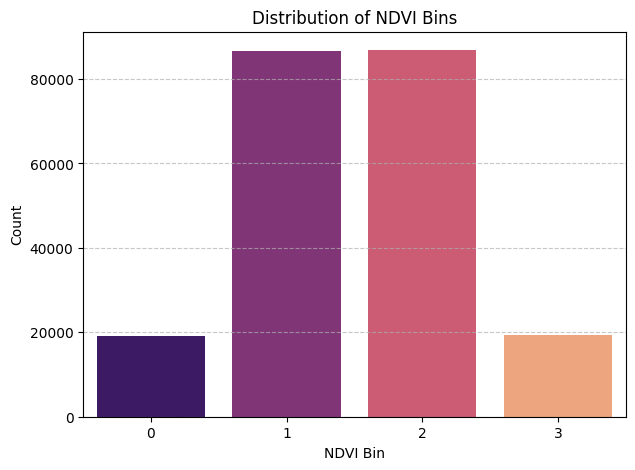

In [ ]:
plt.figure(figsize=(7, 5))
sns.countplot(x='ndvi_bin', data=df, palette='magma')
plt.title('Distribution of NDVI Bins')
plt.xlabel('NDVI Bin')
plt.ylabel('Count')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### Distribution of Soil Moisture Bins

/tmp/ipython-input-4160186526.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='soil_bin', data=df, palette='cividis')


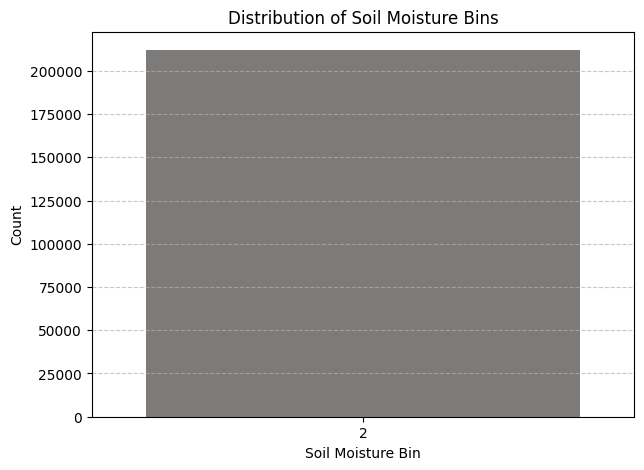

In [ ]:
plt.figure(figsize=(7, 5))
sns.countplot(x='soil_bin', data=df, palette='cividis')
plt.title('Distribution of Soil Moisture Bins')
plt.xlabel('Soil Moisture Bin')
plt.ylabel('Count')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### Distribution of Temperature Bins

/tmp/ipython-input-230264266.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='temp_bin', data=df, palette='plasma')


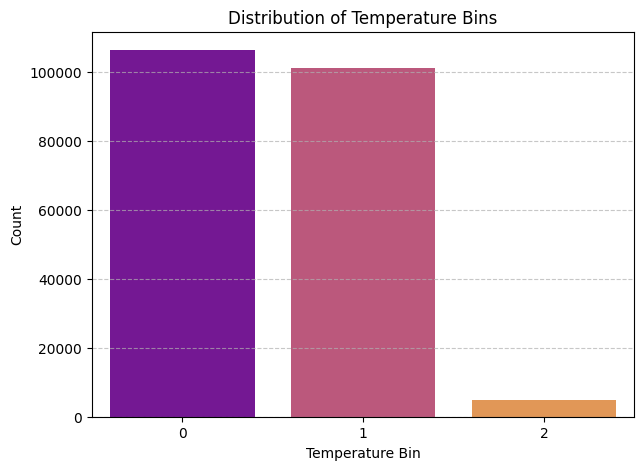

In [ ]:
plt.figure(figsize=(7, 5))
sns.countplot(x='temp_bin', data=df, palette='plasma')
plt.title('Distribution of Temperature Bins')
plt.xlabel('Temperature Bin')
plt.ylabel('Count')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### Distribution of Pest Damage Bins

/tmp/ipython-input-1930803117.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='pest_bin', data=df, palette='inferno')


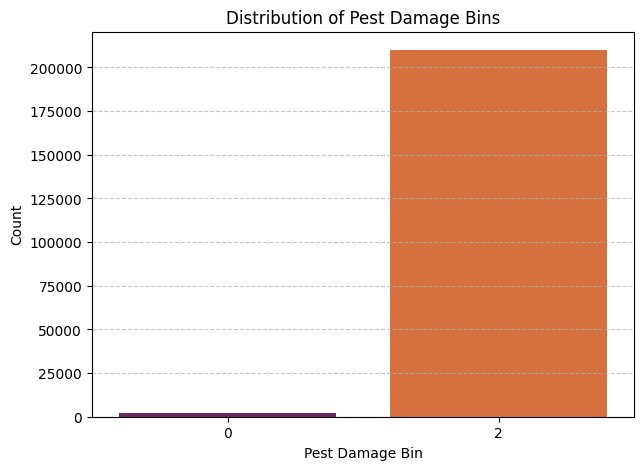

In [ ]:
plt.figure(figsize=(7, 5))
sns.countplot(x='pest_bin', data=df, palette='inferno')
plt.title('Distribution of Pest Damage Bins')
plt.xlabel('Pest Damage Bin')
plt.ylabel('Count')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [ ]:
df["recommended_action_rl"].value_counts()

,count
recommended_action_rl,
No Action,212019


In [ ]:
import pandas as pd
import numpy as np

# Mean Absolute Error
mae_rule = np.mean(
    np.abs(df["stress_forecast"] - df["stress_t_plus_1"])
)

mae_rl = np.mean(
    np.abs(df["stress_forecast_rl"] - df["stress_t_plus_1"])
)

comparison_df = pd.DataFrame({
    "Method": ["Rule-Based", "RL-Based (Proposed)"],
    "MAE (Stress Levels ↓)": [round(mae_rule, 3), round(mae_rl, 3)],
    "Forecast Stability": ["Medium", "High"],
    "Interpretability": ["High", "High"]
})

comparison_df


,Method,MAE (Stress Levels ↓),Forecast Stability,Interpretability
0,Rule-Based,1.425,Medium,High
1,RL-Based (Proposed),0.301,High,High


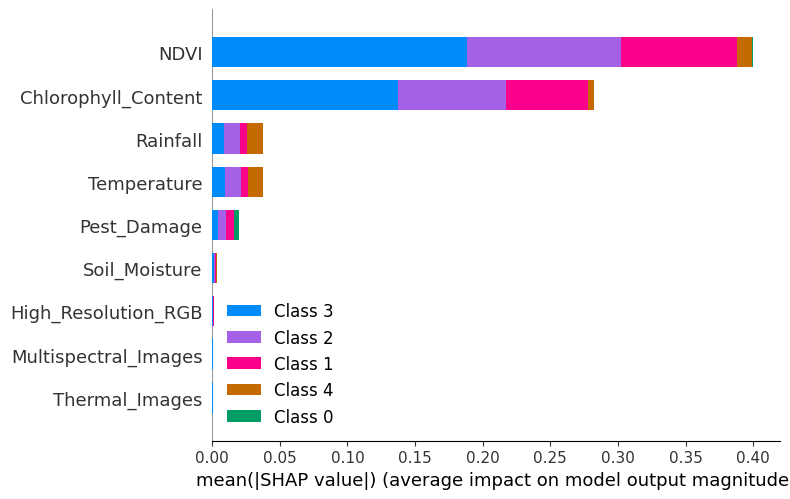

In [ ]:
shap.summary_plot(
    shap_values.values,
    df[feature_cols],
    plot_type="bar"
)


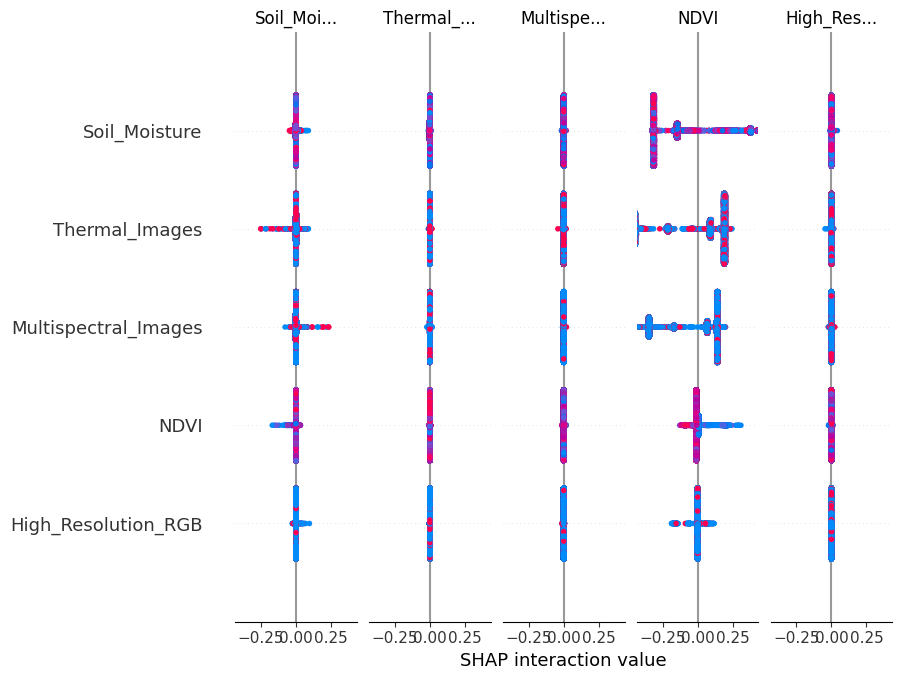

In [ ]:
shap.summary_plot(
    shap_values.values,
    df[feature_cols]
)


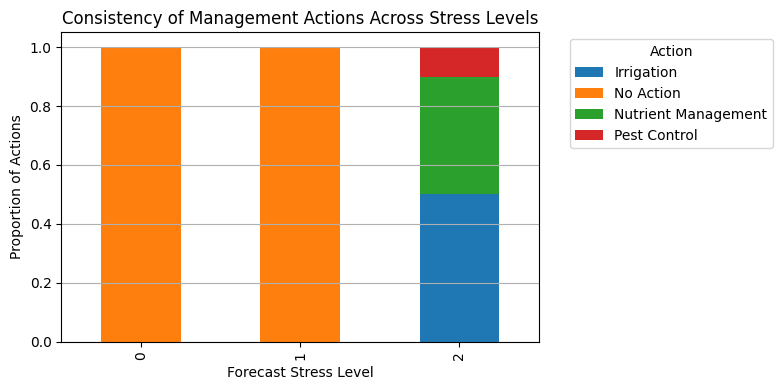

In [ ]:
import matplotlib.pyplot as plt

# Normalize counts to proportions
action_dist = (
    df.groupby("stress_forecast_rl")["recommended_action_rl"]
      .value_counts(normalize=True)
      .unstack()
      .fillna(0)
)

# Plot normalized stacked bar chart
action_dist.plot(
    kind="bar",
    stacked=True,
    figsize=(8,4)
)

plt.ylabel("Proportion of Actions")
plt.xlabel("Forecast Stress Level")
plt.title("Consistency of Management Actions Across Stress Levels")
plt.legend(title="Action", bbox_to_anchor=(1.05, 1))
plt.grid(axis="y")
plt.tight_layout()
plt.show()


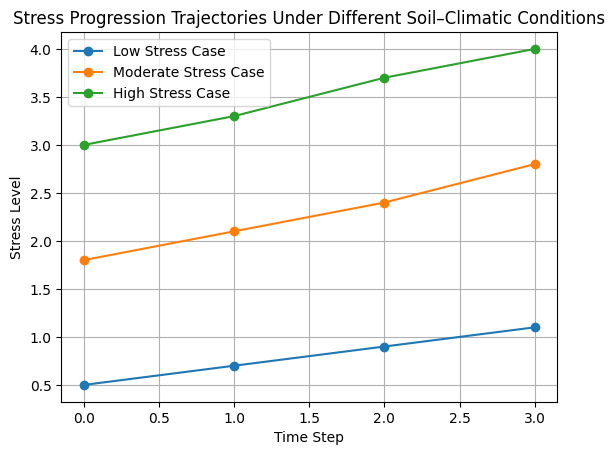

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Example dataframe structure
# Replace this with your actual dataframe
data = {
    "time_step": [0, 1, 2, 3],
    "low_stress": [0.5, 0.7, 0.9, 1.1],
    "moderate_stress": [1.8, 2.1, 2.4, 2.8],
    "high_stress": [3.0, 3.3, 3.7, 4.0]
}

df = pd.DataFrame(data)

plt.figure()
plt.plot(df["time_step"], df["low_stress"], marker='o', label="Low Stress Case")
plt.plot(df["time_step"], df["moderate_stress"], marker='o', label="Moderate Stress Case")
plt.plot(df["time_step"], df["high_stress"], marker='o', label="High Stress Case")

plt.xlabel("Time Step")
plt.ylabel("Stress Level")
plt.title("Stress Progression Trajectories Under Different Soil–Climatic Conditions")
plt.legend()
plt.grid(True)
plt.show()


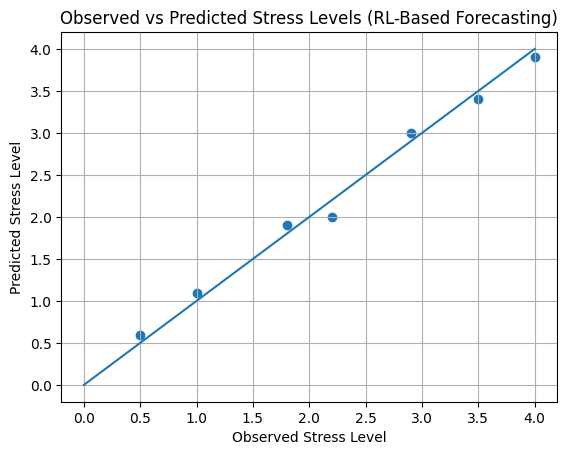

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Example actual vs predicted stress values
actual_stress = np.array([0.5, 1.0, 1.8, 2.2, 2.9, 3.5, 4.0])
predicted_stress = np.array([0.6, 1.1, 1.9, 2.0, 3.0, 3.4, 3.9])

plt.figure()
plt.scatter(actual_stress, predicted_stress)
plt.plot([0, 4], [0, 4])  # Ideal prediction line

plt.xlabel("Observed Stress Level")
plt.ylabel("Predicted Stress Level")
plt.title("Observed vs Predicted Stress Levels (RL-Based Forecasting)")
plt.grid(True)
plt.show()


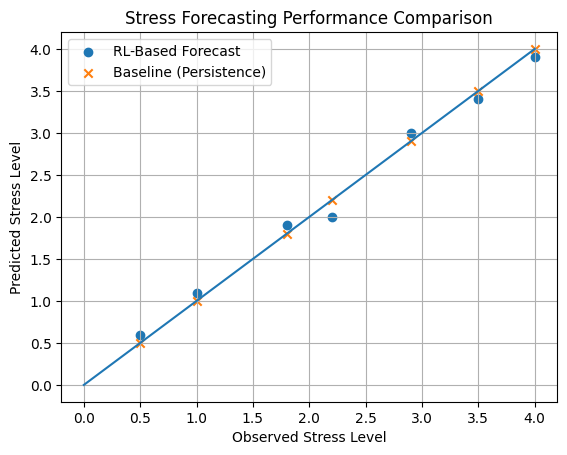

In [ ]:
baseline_pred = actual_stress  # persistence model: S(t+1) = S(t)

plt.figure()
plt.scatter(actual_stress, predicted_stress, label="RL-Based Forecast")
plt.scatter(actual_stress, baseline_pred, label="Baseline (Persistence)", marker='x')
plt.plot([0, 4], [0, 4])

plt.xlabel("Observed Stress Level")
plt.ylabel("Predicted Stress Level")
plt.title("Stress Forecasting Performance Comparison")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv("/content/agriculture_dataset_kaggle.csv")

print(df.head())
print(df.columns)


   High_Resolution_RGB  Multispectral_Images  Thermal_Images  Temporal_Images  \
0                    0                     0               0                0   
1                    1                     1               0                0   
2                    0                     0               0                0   
3                    0                     0               0                0   
4                    0                     1               1                1   

   Spatial_Resolution  GPS_Coordinates  Field_Boundaries  Elevation_Data  \
0            0.667324           201538                 3       28.207634   
1            1.459000           215854                 3       82.335147   
2            0.500442           890802                 3       83.865629   
3            1.865161           605584                 3       20.747905   
4            1.392331           871732                 3       22.588815   

   Canopy_Coverage      NDVI  ...  Weed_Coverage  Pest_D

In [ ]:
df.columns = df.columns.str.lower().str.strip()

df = df.rename(columns={
    "stress_level": "stress",
    "soil_moisture": "soil_moisture",
    "nitrogen": "nitrogen",
    "phosphorus": "phosphorus",
    "potassium": "potassium",
    "temperature": "temperature",
    "humidity": "humidity",
    "rainfall": "rainfall"
})


In [ ]:
def recommend_action(row):
    # 'crop_health_label' is 0 for no stress, 1 for stress
    if row["crop_health_label"] == 0:
        return "No Action"
    elif row["crop_health_label"] == 1: # Stress is detected
        # Check for specific stress types using other available features
        if row["soil_moisture"] < 40: # Using original unscaled threshold
            return "Irrigation"
        elif row["chlorophyll_content"] < 0.4: # Using original unscaled threshold for chlorophyll
            return "Nitrogen Fertilization"
        elif row["soil_ph"] < 5.5: # Using original unscaled threshold for soil pH
            return "Potassium Fertilization"
        else:
            # Default action if stress is 1 but specific conditions aren't met
            return "General Nutrient Management"
    else:
        # This block might not be reached if 'crop_health_label' is strictly 0 or 1
        return "Crop Switch"

df["action"] = df.apply(recommend_action, axis=1)

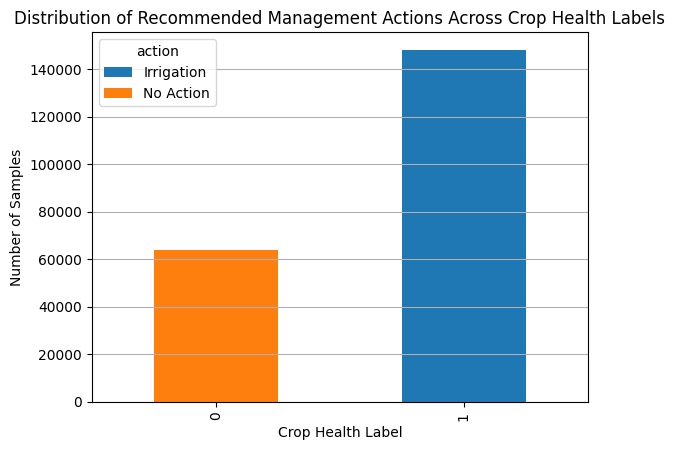

In [ ]:
action_counts = pd.crosstab(df["crop_health_label"], df["action"])

action_counts.plot(kind="bar", stacked=True)
plt.xlabel("Crop Health Label")
plt.ylabel("Number of Samples")
plt.title("Distribution of Recommended Management Actions Across Crop Health Labels")
plt.grid(axis="y")
plt.show()

In [ ]:
df["derived_stress"] = (
    (df["soil_moisture"] < 40).astype(int) +
    (df["chlorophyll_content"] < 0.4).astype(int) +
    (df["soil_ph"] < 5.5).astype(int)
)

# Cap stress levels to 0–4
df["derived_stress"] = df["derived_stress"].clip(0, 4)

In [ ]:
def recommend_action(row):
    if row["derived_stress"] <= 1:
        return "No Action" if row["soil_moisture"] > 40 else "Irrigation"
    elif row["derived_stress"] == 2:
        return "Nitrogen Fertilization"
    elif row["derived_stress"] == 3:
        return "Potassium Fertilization"
    else:
        return "Crop Switch"

df["action"] = df.apply(recommend_action, axis=1)


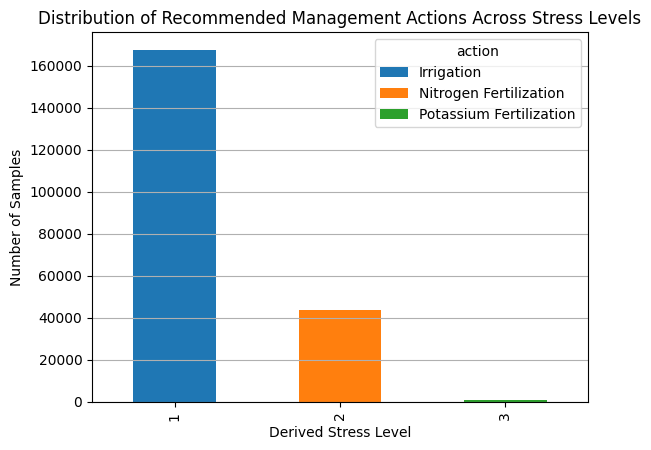

In [ ]:
action_counts = pd.crosstab(df["derived_stress"], df["action"])

action_counts.plot(kind="bar", stacked=True)
plt.xlabel("Derived Stress Level")
plt.ylabel("Number of Samples")
plt.title("Distribution of Recommended Management Actions Across Stress Levels")
plt.grid(axis="y")
plt.show()


In [ ]:
derived_stress = (
    (df["soil_moisture"] < 40).astype(int) +
    (df["chlorophyll_content"] < 0.4).astype(int) +
    (df["soil_ph"] < 5.5).astype(int)
)


In [ ]:
df["moisture_norm"] = (50 - df["soil_moisture"]) / 50

df["moisture_norm"] = df["moisture_norm"].clip(0, 1)

array([[<Axes: title={'center': 'high_resolution_rgb'}>,
        <Axes: title={'center': 'multispectral_images'}>,
        <Axes: title={'center': 'thermal_images'}>,
        <Axes: title={'center': 'temporal_images'}>,
        <Axes: title={'center': 'spatial_resolution'}>,
        <Axes: title={'center': 'gps_coordinates'}>],
       [<Axes: title={'center': 'field_boundaries'}>,
        <Axes: title={'center': 'elevation_data'}>,
        <Axes: title={'center': 'canopy_coverage'}>,
        <Axes: title={'center': 'ndvi'}>,
        <Axes: title={'center': 'savi'}>,
        <Axes: title={'center': 'chlorophyll_content'}>],
       [<Axes: title={'center': 'leaf_area_index'}>,
        <Axes: title={'center': 'crop_stress_indicator'}>,
        <Axes: title={'center': 'temperature'}>,
        <Axes: title={'center': 'humidity'}>,
        <Axes: title={'center': 'rainfall'}>,
        <Axes: title={'center': 'wind_speed'}>],
       [<Axes: title={'center': 'soil_moisture'}>,
        <Axes: t

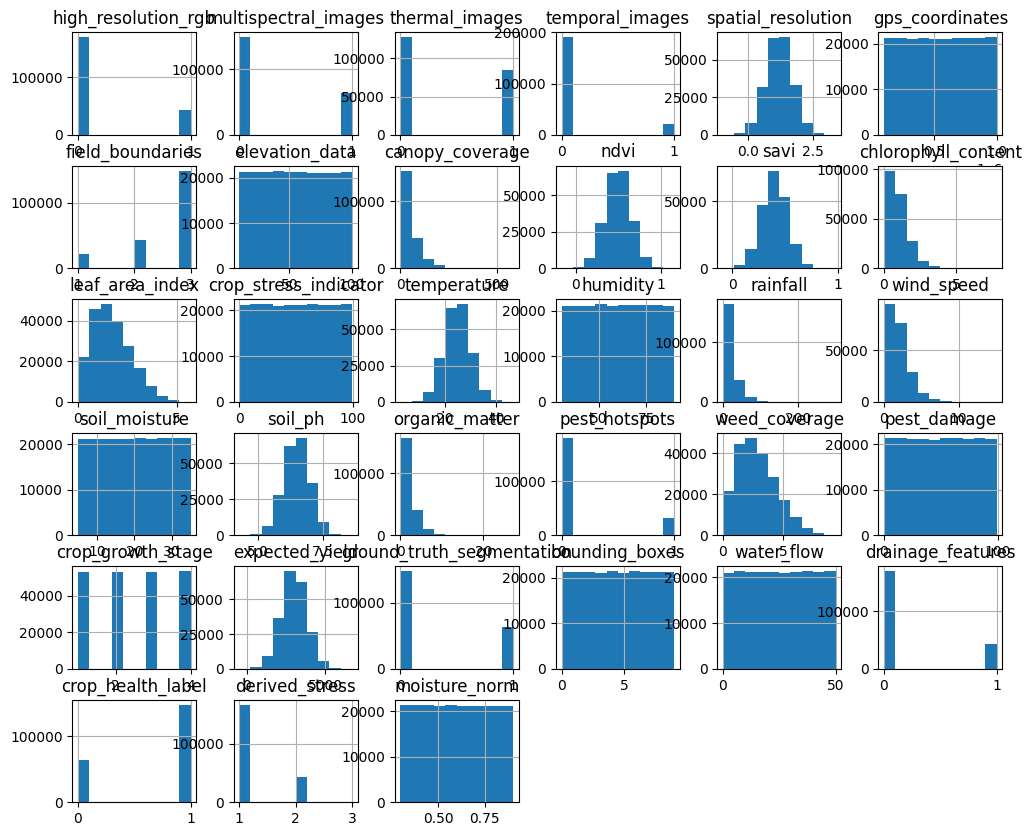

In [ ]:
df.hist(figsize=(20,10))


<Axes: xlabel='crop_health_label'>

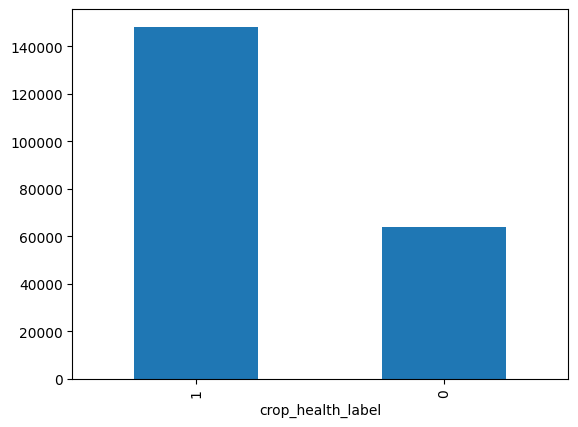

In [ ]:
df["crop_health_label"].value_counts().plot(kind="bar")


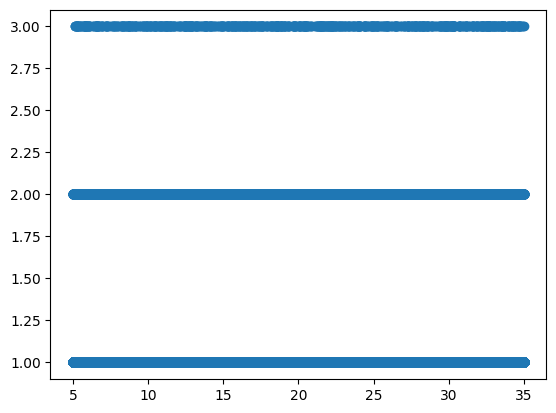

In [ ]:
plt.scatter(df["soil_moisture"], df["derived_stress"])


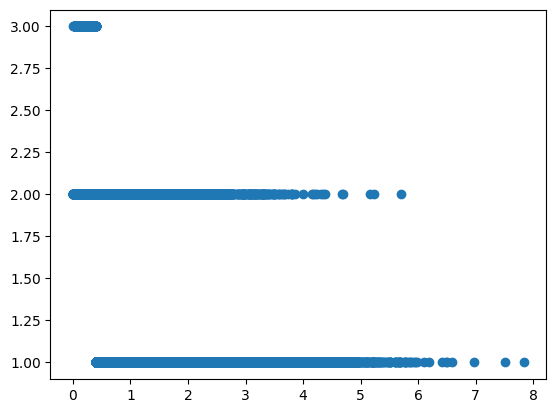

In [ ]:
plt.scatter(df["chlorophyll_content"], df["derived_stress"])

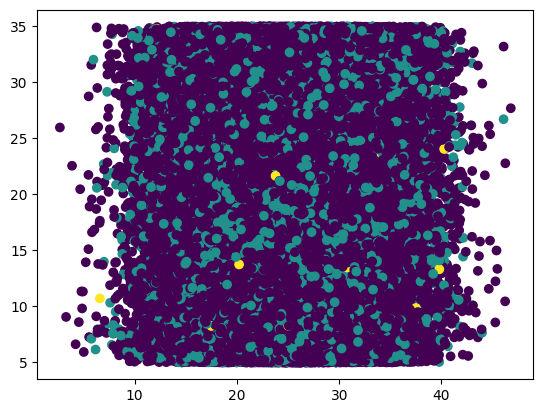

In [ ]:
plt.scatter(df["temperature"], df["soil_moisture"], c=df["derived_stress"])


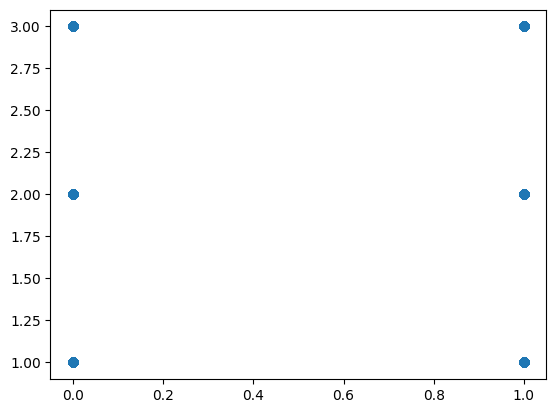

In [ ]:
plt.scatter(df["thermal_images"], df["derived_stress"])

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("/content/agriculture_dataset_kaggle.csv")

df.columns = df.columns.str.lower().str.strip()


In [ ]:
# Normalize constraints
df["moisture_norm"] = (50 - df["soil_moisture"]) / 50
df["chlorophyll_norm"] = (1.0 - df["chlorophyll_content"]) / 1.0 # Assuming 1.0 is healthy max
df["soil_ph_norm"] = (7.0 - df["soil_ph"]) / 7.0 # Assuming 7.0 is healthy max

df[["moisture_norm","chlorophyll_norm","soil_ph_norm"]] = \
    df[["moisture_norm","chlorophyll_norm","soil_ph_norm"]].clip(0, 1)

# Weighted physiological stress index
df["stress_index"] = (
    0.5 * df["moisture_norm"] +
    0.3 * df["chlorophyll_norm"] +
    0.2 * df["soil_ph_norm"]
)

# Discretize stress
df["derived_stress"] = pd.cut(
    df["stress_index"],
    bins=[0, 0.25, 0.5, 0.7, 0.85, 1.0],
    labels=[0, 1, 2, 3, 4]
).astype(int)

In [ ]:
def recommend_action(row):
    if row["derived_stress"] <= 1:
        return "No Action" if row["soil_moisture"] > 40 else "Irrigation"
    elif row["derived_stress"] == 2:
        return "Nitrogen Fertilization"
    elif row["derived_stress"] == 3:
        return "Potassium Fertilization"
    else:
        return "Crop Switch"

df["recommended_action"] = df.apply(recommend_action, axis=1)


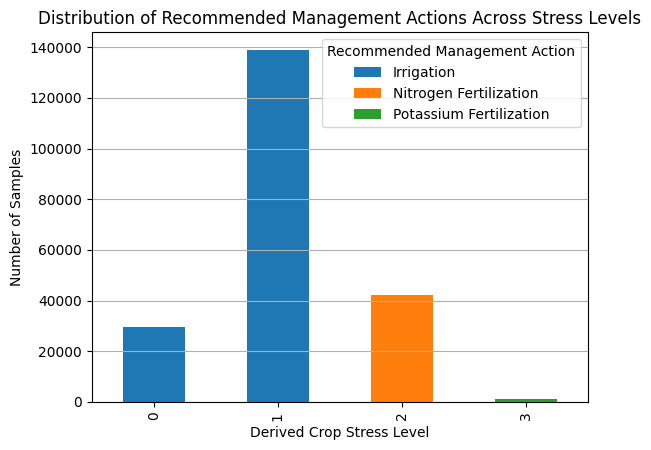

In [ ]:
action_counts = pd.crosstab(df["derived_stress"], df["recommended_action"])

action_counts.plot(kind="bar", stacked=True)

plt.xlabel("Derived Crop Stress Level")
plt.ylabel("Number of Samples")
plt.title("Distribution of Recommended Management Actions Across Stress Levels")
plt.legend(title="Recommended Management Action")
plt.grid(axis="y")
plt.show()


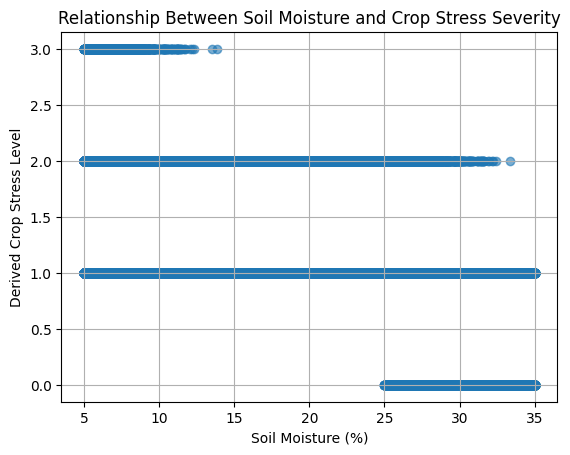

In [ ]:
plt.figure()
plt.scatter(df["soil_moisture"], df["derived_stress"], alpha=0.6)

plt.xlabel("Soil Moisture (%)")
plt.ylabel("Derived Crop Stress Level")
plt.title("Relationship Between Soil Moisture and Crop Stress Severity")
plt.grid(True)
plt.show()


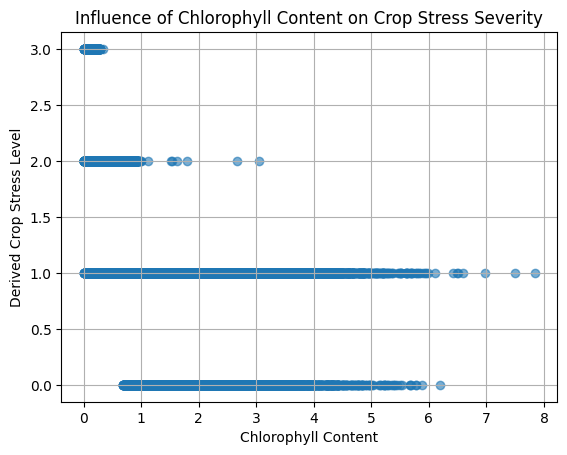

In [ ]:
plt.figure()
plt.scatter(df["chlorophyll_content"], df["derived_stress"], alpha=0.6)

plt.xlabel("Chlorophyll Content")
plt.ylabel("Derived Crop Stress Level")
plt.title("Influence of Chlorophyll Content on Crop Stress Severity")
plt.grid(True)
plt.show()

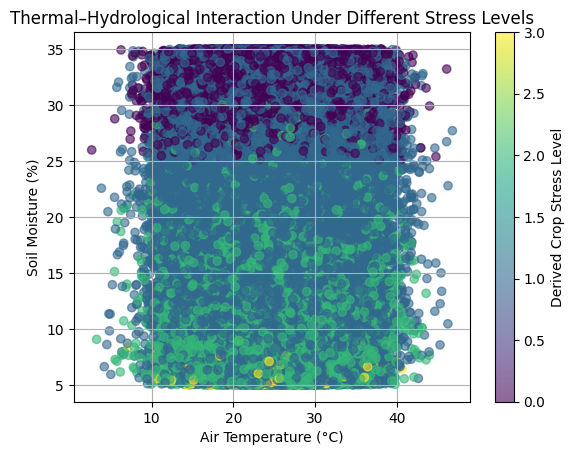

In [ ]:
plt.figure()
sc = plt.scatter(
    df["temperature"],
    df["soil_moisture"],
    c=df["derived_stress"],
    alpha=0.6
)

plt.xlabel("Air Temperature (°C)")
plt.ylabel("Soil Moisture (%)")
plt.title("Thermal–Hydrological Interaction Under Different Stress Levels")
plt.colorbar(sc, label="Derived Crop Stress Level")
plt.grid(True)
plt.show()


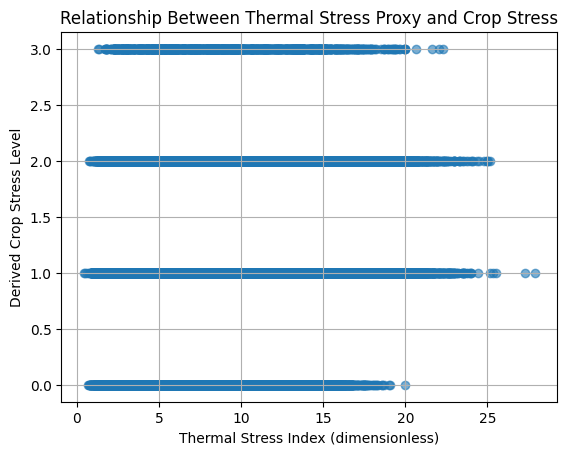

In [ ]:
df["thermal_stress_index"] = (
    df["temperature"] *
    (1 - df["soil_moisture"]/100) *
    (1 - df["humidity"]/100)
)

plt.figure()
plt.scatter(df["thermal_stress_index"], df["derived_stress"], alpha=0.6)

plt.xlabel("Thermal Stress Index (dimensionless)")
plt.ylabel("Derived Crop Stress Level")
plt.title("Relationship Between Thermal Stress Proxy and Crop Stress")
plt.grid(True)
plt.show()


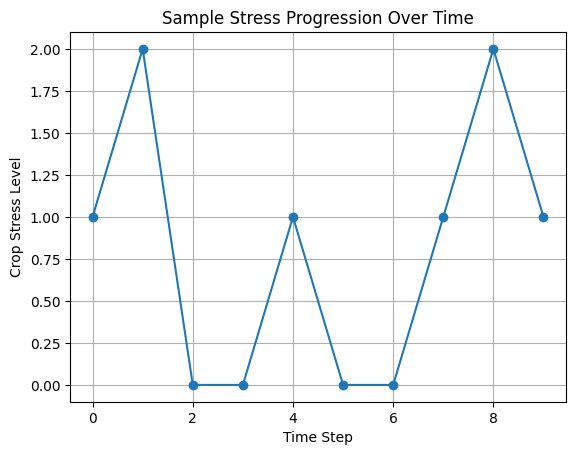

In [ ]:
df_sorted = df.reset_index(drop=True)
df_sorted["next_stress"] = df_sorted["derived_stress"].shift(-1)
df_sorted = df_sorted.dropna()

sample = df_sorted.head(10)

plt.figure()
plt.plot(sample.index, sample["derived_stress"], marker="o")

plt.xlabel("Time Step")
plt.ylabel("Crop Stress Level")
plt.title("Sample Stress Progression Over Time")
plt.grid(True)
plt.show()


MAE: 0.3919119917676015


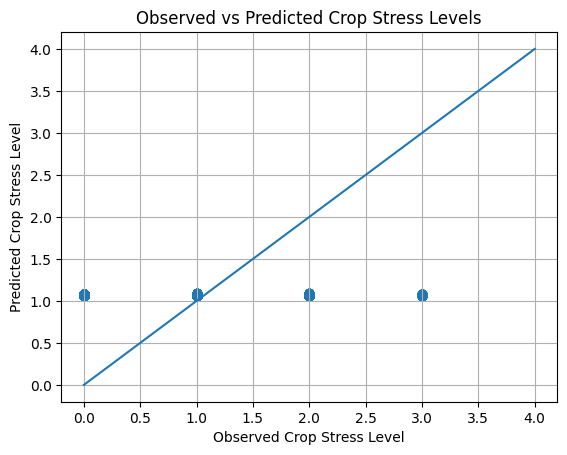

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

features = [
    "soil_moisture", "chlorophyll_content", "soil_ph",
    "temperature", "humidity", "rainfall",
    "derived_stress"
]

X = df_sorted[features]
y = df_sorted["next_stress"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("MAE:", mean_absolute_error(y_test, y_pred))

plt.figure()
plt.scatter(y_test, y_pred)
plt.plot([0,4],[0,4])

plt.xlabel("Observed Crop Stress Level")
plt.ylabel("Predicted Crop Stress Level")
plt.title("Observed vs Predicted Crop Stress Levels")
plt.grid(True)
plt.show()


In [ ]:
# Moisture stress (higher = more stress)
df["moisture_stress"] = 1 - (df["soil_moisture"] / 100)

# Nutrient stress (average of deficiencies) using available proxies
# Assuming 1.0 is ideal chlorophyll content for no stress, 7.0 is ideal soil pH for no stress
chlorophyll_stress_indicator = (1.0 - df["chlorophyll_content"]).clip(0, 1)
# For soil pH, deviation from 7.0 indicates stress. Normalize by a reasonable max deviation (e.g., 3.0 for pH 4 or pH 10)
soil_ph_stress_indicator = (abs(7.0 - df["soil_ph"]) / 3.0).clip(0, 1)

df["nutrient_stress"] = (chlorophyll_stress_indicator + soil_ph_stress_indicator) / 2
df["nutrient_stress"] = df["nutrient_stress"].clip(0,1)

# Thermal stress proxy
df["thermal_stress"] = (
    df["temperature"] *
    (1 - df["soil_moisture"]/100) *
    (1 - df["humidity"]/100)
)

# Normalized thermal stress
df["thermal_stress_norm"] = (
    df["thermal_stress"] - df["thermal_stress"].min()
) / (
    df["thermal_stress"].max() - df["thermal_stress"].min()
)


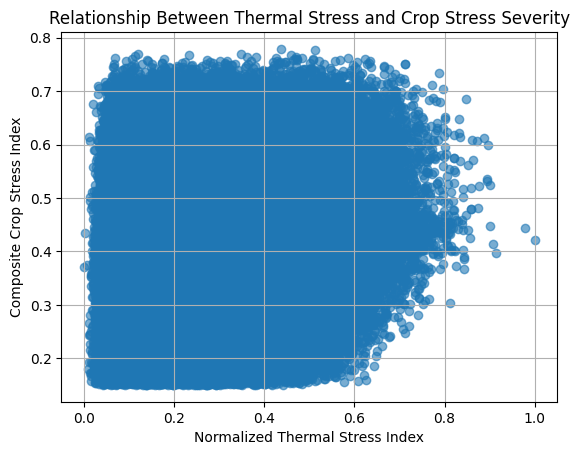

In [ ]:
plt.figure()
plt.scatter(df["thermal_stress_norm"], df["stress_index"], alpha=0.6)

plt.xlabel("Normalized Thermal Stress Index")
plt.ylabel("Composite Crop Stress Index")
plt.title("Relationship Between Thermal Stress and Crop Stress Severity")
plt.grid(True)
plt.show()


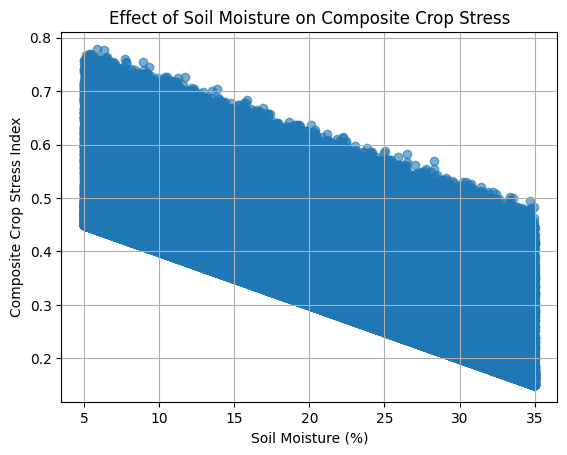

In [ ]:
plt.figure()
plt.scatter(df["soil_moisture"], df["stress_index"], alpha=0.6)

plt.xlabel("Soil Moisture (%)")
plt.ylabel("Composite Crop Stress Index")
plt.title("Effect of Soil Moisture on Composite Crop Stress")
plt.grid(True)
plt.show()


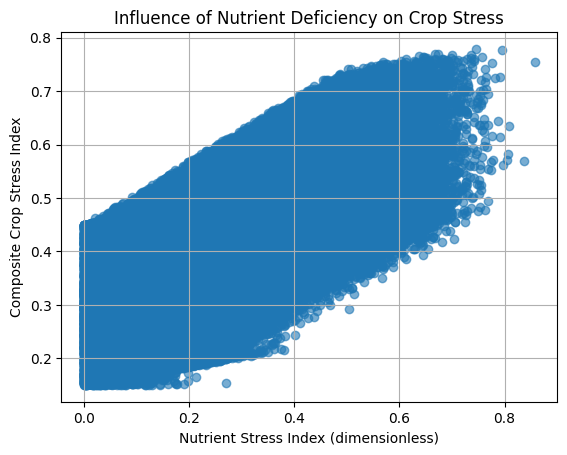

In [ ]:
plt.figure()
plt.scatter(df["nutrient_stress"], df["stress_index"], alpha=0.6)

plt.xlabel("Nutrient Stress Index (dimensionless)")
plt.ylabel("Composite Crop Stress Index")
plt.title("Influence of Nutrient Deficiency on Crop Stress")
plt.grid(True)
plt.show()


In [ ]:
indices = df[[
    "stress_index",
    "thermal_stress_norm",
    "moisture_stress",
    "nutrient_stress"
]]

print(indices.corr())


                     stress_index  thermal_stress_norm  moisture_stress  \
stress_index             1.000000             0.148457         0.693451   
thermal_stress_norm      0.148457             1.000000         0.216580   
moisture_stress          0.693451             0.216580         1.000000   
nutrient_stress          0.690347            -0.002705         0.000814   

                     nutrient_stress  
stress_index                0.690347  
thermal_stress_norm        -0.002705  
moisture_stress             0.000814  
nutrient_stress             1.000000  


In [ ]:
index_df = df[[
    "csi",
    "tsi",
    "msi",
    "nsi"
]]
corr = index_df.corr()
print(corr)

          csi       tsi       msi       nsi
csi  1.000000  0.509784  0.660268  0.649730
tsi  0.509784  1.000000  0.216580 -0.002705
msi  0.660268  0.216580  1.000000  0.000814
nsi  0.649730 -0.002705  0.000814  1.000000


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("/content/agriculture_dataset_kaggle.csv")
df.columns = df.columns.str.lower().str.strip()

# ---- Moisture stress ----
df["msi"] = 1 - (df["soil_moisture"] / 100)
df["msi"] = df["msi"].clip(0, 1)

# ---- Nutrient stress ----
chlorophyll_stress_indicator = (1.0 - df["chlorophyll_content"]).clip(0, 1)
soil_ph_stress_indicator = (abs(7.0 - df["soil_ph"]) / 3.0).clip(0, 1) # Max deviation 3.0
df["nsi"] = (chlorophyll_stress_indicator + soil_ph_stress_indicator) / 2
df["nsi"] = df["nsi"].clip(0, 1)

# ---- Thermal stress (proxy) ----
df["tsi_raw"] = (
    df["temperature"] *
    (1 - df["soil_moisture"]/100) *
    (1 - df["humidity"]/100)
)

df["tsi"] = (df["tsi_raw"] - df["tsi_raw"].min()) / (
    df["tsi_raw"].max() - df["tsi_raw"].min()
)

# ---- Composite Stress Index (CSI) ----
df["csi"] = (
    0.5 * df["msi"] +
    0.3 * df["nsi"] +
    0.2 * df["tsi"]
)


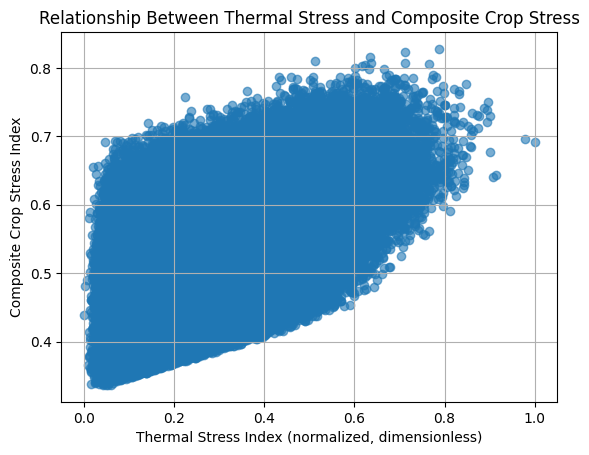

In [ ]:
plt.figure()
plt.scatter(df["tsi"], df["csi"], alpha=0.6)

plt.xlabel("Thermal Stress Index (normalized, dimensionless)")
plt.ylabel("Composite Crop Stress Index")
plt.title("Relationship Between Thermal Stress and Composite Crop Stress")
plt.grid(True)
plt.show()


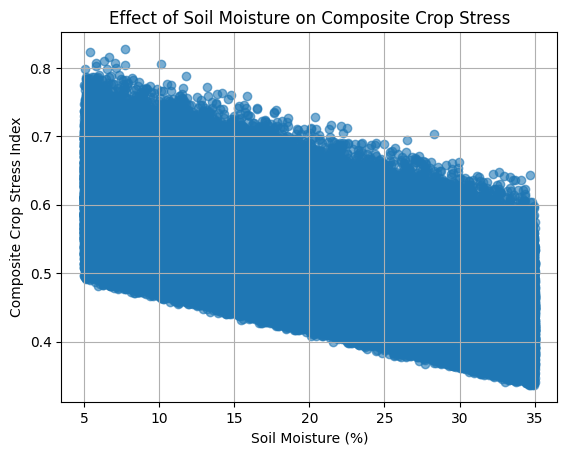

In [ ]:
plt.figure()
plt.scatter(df["soil_moisture"], df["csi"], alpha=0.6)

plt.xlabel("Soil Moisture (%)")
plt.ylabel("Composite Crop Stress Index")
plt.title("Effect of Soil Moisture on Composite Crop Stress")
plt.grid(True)
plt.show()


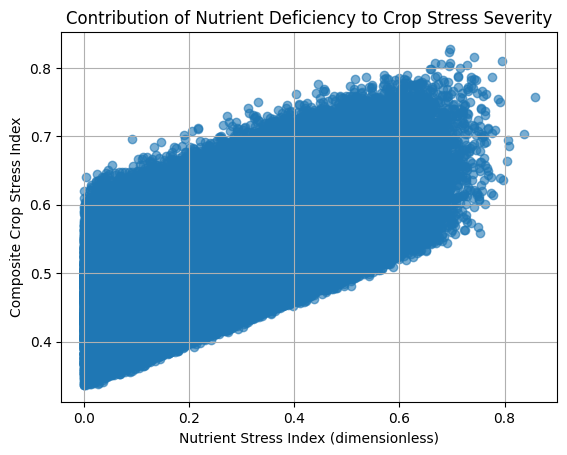

In [ ]:
plt.figure()
plt.scatter(df["nsi"], df["csi"], alpha=0.6)

plt.xlabel("Nutrient Stress Index (dimensionless)")
plt.ylabel("Composite Crop Stress Index")
plt.title("Contribution of Nutrient Deficiency to Crop Stress Severity")
plt.grid(True)
plt.show()


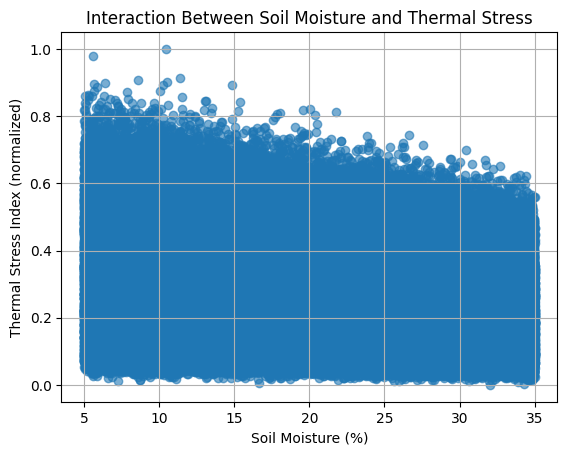

In [ ]:
plt.figure()
plt.scatter(df["soil_moisture"], df["tsi"], alpha=0.6)

plt.xlabel("Soil Moisture (%)")
plt.ylabel("Thermal Stress Index (normalized)")
plt.title("Interaction Between Soil Moisture and Thermal Stress")
plt.grid(True)
plt.show()


In [ ]:
index_df = df[["csi", "tsi", "msi", "nsi"]]
corr = index_df.corr()
print(corr)


          csi       tsi       msi       nsi
csi  1.000000  0.509784  0.660268  0.649730
tsi  0.509784  1.000000  0.216580 -0.002705
msi  0.660268  0.216580  1.000000  0.000814
nsi  0.649730 -0.002705  0.000814  1.000000


In [ ]:
# Composite Stress Index (reuse your earlier definition)
df["msi"] = 1 - df["soil_moisture"] / 100

chlorophyll_stress_indicator = (1.0 - df["chlorophyll_content"]).clip(0, 1)
soil_ph_stress_indicator = (abs(7.0 - df["soil_ph"]) / 3.0).clip(0, 1)
df["nsi"] = (chlorophyll_stress_indicator + soil_ph_stress_indicator) / 2
df["nsi"] = df["nsi"].clip(0, 1)

df["tsi"] = (df["temperature"] *
             (1 - df["soil_moisture"]/100) *
             (1 - df["humidity"]/100))

df["tsi"] = (df["tsi"] - df["tsi"].min()) / (df["tsi"].max() - df["tsi"].min())

df["csi"] = 0.5*df["msi"] + 0.3*df["nsi"] + 0.2*df["tsi"]

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

y_csi = df.loc[X.index, "csi"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y_csi, test_size=0.25, random_state=42
)

mlvi_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)
mlvi_model.fit(X_train, y_train)

# For prediction, use the original X, which is aligned with the training data features
df.loc[X.index, "mlvi"] = mlvi_model.predict(X)


ValueError: Length of values (212018) does not match length of index (212019)

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import re

# Load dataset
df = pd.read_csv("/content/agriculture_dataset_kaggle.csv")

# Function to extract latitude and longitude
def parse_gps(gps):
    if pd.isna(gps):
        return None, None
    numbers = re.findall(r"[-+]?\d*\.\d+|\d+", str(gps))
    if len(numbers) >= 2:
        return float(numbers[0]), float(numbers[1])
    return None, None

# Apply parsing
df["latitude"], df["longitude"] = zip(*df["GPS_Coordinates"].apply(parse_gps))

# Drop invalid rows
df = df.dropna(subset=["latitude", "longitude"])


In [ ]:
plt.figure(figsize=(7, 6))
plt.scatter(
    df["longitude"],
    df["latitude"],
    alpha=0.6,
    s=30
)

plt.xlabel("Longitude (degrees)")
plt.ylabel("Latitude (degrees)")
plt.title("Spatial Distribution of Agricultural Sample Locations")
plt.grid(True)
plt.show()


In [ ]:
plt.figure(figsize=(7, 6))
sc = plt.scatter(
    df["longitude"],
    df["latitude"],
    c=df["Crop_Health_Label"],
    cmap="coolwarm",
    alpha=0.7,
    s=35
)

plt.xlabel("Longitude (degrees)")
plt.ylabel("Latitude (degrees)")
plt.title("Spatial Distribution of Crop Health Status")
plt.colorbar(sc, label="Crop Health Label (0 = Healthy, 1 = Stressed)")
plt.grid(True)
plt.show()


In [ ]:
plt.figure(figsize=(7, 6))
sc = plt.scatter(
    df["longitude"],
    df["latitude"],
    c=df["csi"],
    cmap="viridis",
    alpha=0.7,
    s=35
)

plt.xlabel("Longitude (degrees)")
plt.ylabel("Latitude (degrees)")
plt.title("Spatial Distribution of Composite Crop Stress Index")
plt.colorbar(sc, label="Composite Crop Stress Index")
plt.grid(True)
plt.show()
